# Tercera entrega – Minería de Datos
## Revisión, corrección y evaluación del modelo de predicción de enfermedad cardíaca

**Estudiante:** Sebastian Navarro Rojas  
**Proyecto:** Clasificación binaria de `heart_disease`  
**Dataset:** `patient_dataset.csv`
**Entorno previsto:** Google Colab

### Propósito de esta libreta
Esta libreta continúa el trabajo de las rúbricas 1 y 2. En este libro quiero reconocer, corregir y mejorar mis errores. No repite el proyecto desde cero: conserva el problema y el conjunto de datos, pero revisa la calidad del pipeline, evita fuga de información, compara modelos con validación cruzada y deja preparado el pipeline final para utilizarlo en Streamlit.




## 1. Antecedentes y resultados de la segunda rúbrica

En la segunda rúbrica se trabajó con 6.000 registros y 16 columnas. La variable objetivo fue `heart_disease`. Se compararon Regresión Logística y Árbol de Decisión.

Resultados históricos registrados en el notebook anterior:

| Modelo | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Regresión Logística | 0,4958 | 0,4933 | 0,4281 | 0,4584 |
| Árbol de Decisión | 0,4950 | 0,4962 | 0,8813 | 0,6349 |

Estos valores se conservan como referencia histórica. Los resultados nuevos se calcularán con un pipeline corregido; por ello, la comparación debe interpretarse teniendo en cuenta los cambios en el preprocesamiento.

**Problema detectado:** en la segunda rúbrica se imputaron valores faltantes antes de dividir entrenamiento y prueba. Para reducir el riesgo de fuga de información, en esta versión la imputación y las transformaciones se ajustan dentro del pipeline usando únicamente los datos de entrenamiento de cada partición.


## 2. Preparación del entorno y carga del dataset



In [1]:

try:
    from google.colab import files
    import os
    if not os.path.exists("patient_dataset.csv"):
        uploaded = files.upload()
except ImportError:
    pass

RUTA_DATASET = "patient_dataset.csv"

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
sns.set_theme(style="whitegrid")

df = pd.read_csv(RUTA_DATASET)

print("Dimensiones:", df.shape)
display(df.head())
print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))


Saving patient_dataset.csv to patient_dataset.csv
Dimensiones: (6000, 16)


,age,gender,chest_pain_type,blood_pressure,cholesterol,max_heart_rate,exercise_angina,plasma_glucose,skin_thickness,insulin,bmi,diabetes_pedigree,hypertension,heart_disease,residence_type,smoking_status
0,24,1.0,4,250,139,212,0,108.0,33.0,109.0,37.999303,0.480277,1,1,Urban,Smoker
1,29,0.0,4,132,187,147,0,202.0,42.0,NaN,25.588346,0.283986,1,1,Urban,Unknown
2,46,0.0,3,271,185,193,0,149.0,43.0,102.0,37.892029,2.472309,1,0,Rural,Non-Smoker
3,73,NaN,2,102,200,125,0,105.0,77.0,165.0,18.660241,1.472052,0,1,Rural,Smoker
4,49,1.0,3,91,163,192,0,162.0,31.0,170.0,12.767980,0.537627,1,1,Rural,Smoker



Tipos de datos:


,tipo
age,int64
gender,float64
chest_pain_type,int64
blood_pressure,int64
cholesterol,int64
max_heart_rate,int64
exercise_angina,int64
plasma_glucose,float64
skin_thickness,float64
insulin,float64


## 3. Descripción y diagnóstico de calidad

La variable objetivo es `heart_disease` (0 = clase negativa y 1 = clase positiva, según la codificación utilizada en el proyecto). Antes de entrenar, se revisan valores faltantes, duplicados, categorías y rangos observados.




In [2]:
TARGET = "heart_disease"

assert TARGET in df.columns, f"No se encontró la columna objetivo {TARGET}"
assert df[TARGET].notna().all(), "La variable objetivo contiene valores faltantes."
assert set(df[TARGET].unique()).issubset({0, 1}), "La variable objetivo no está codificada únicamente como 0 y 1."

print("Valores faltantes por columna:")
display(df.isna().sum().sort_values(ascending=False).to_frame("faltantes"))
print("Filas duplicadas:", df.duplicated().sum())
print("\nDistribución de la variable objetivo:")
display(df[TARGET].value_counts().sort_index().to_frame("cantidad"))
display((df[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_frame("porcentaje"))

print("\nResumen de variables numéricas:")
display(df.describe().T)


Valores faltantes por columna:


,faltantes
skin_thickness,614
plasma_glucose,609
insulin,568
gender,472
residence_type,455
blood_pressure,0
chest_pain_type,0
age,0
exercise_angina,0
max_heart_rate,0


Filas duplicadas: 0

Distribución de la variable objetivo:


,cantidad
heart_disease,
0,3011
1,2989


,porcentaje
heart_disease,
0,50.18
1,49.82



Resumen de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
age,6000.0,53.657833,21.018382,18.000000,36.000000,53.000000,72.000000,90.000000
gender,5528.0,0.497648,0.500040,0.000000,0.000000,0.000000,1.000000,1.000000
chest_pain_type,6000.0,2.518500,1.124071,1.000000,2.000000,3.000000,4.000000,4.000000
blood_pressure,6000.0,134.277167,48.303001,0.000000,109.000000,135.000000,161.000000,300.000000
cholesterol,6000.0,209.844667,52.840432,120.000000,164.000000,210.000000,257.000000,300.000000
max_heart_rate,6000.0,144.996000,43.583318,70.000000,108.000000,144.000000,183.000000,220.000000
exercise_angina,6000.0,0.503167,0.500032,0.000000,0.000000,1.000000,1.000000,1.000000
plasma_glucose,5391.0,161.119644,52.434693,70.000000,116.000000,162.000000,206.000000,250.000000
skin_thickness,5386.0,59.964723,23.264030,20.000000,40.000000,60.000000,80.000000,100.000000
insulin,5432.0,129.601252,29.207479,80.000000,105.000000,129.000000,155.000000,180.000000


In [3]:
# Valores únicos de las columnas categóricas o codificadas
for col in ["gender", "chest_pain_type", "exercise_angina", "hypertension",
            "residence_type", "smoking_status"]:
    if col in df.columns:
        print(f"{col}: {sorted(df[col].dropna().astype(str).unique().tolist())}")

# Revisión específica de presión arterial y otras variables clínicas
for col in ["blood_pressure", "cholesterol", "max_heart_rate",
            "plasma_glucose", "skin_thickness", "insulin", "bmi"]:
    if col in df.columns:
        print(f"{col}: mínimo={df[col].min()}, máximo={df[col].max()}, ceros={(df[col] == 0).sum()}")


gender: ['0.0', '1.0']
chest_pain_type: ['1', '2', '3', '4']
exercise_angina: ['0', '1']
hypertension: ['0', '1']
residence_type: ['Rural', 'Urban']
smoking_status: ['Non-Smoker', 'Smoker', 'Unknown']
blood_pressure: mínimo=0, máximo=300, ceros=11
cholesterol: mínimo=120, máximo=300, ceros=0
max_heart_rate: mínimo=70, máximo=220, ceros=0
plasma_glucose: mínimo=70.0, máximo=250.0, ceros=0
skin_thickness: mínimo=20.0, máximo=100.0, ceros=0
insulin: mínimo=80.0, máximo=180.0, ceros=0
bmi: mínimo=10.006670046109978, máximo=49.99944877125587, ceros=0


## 4. Visualizaciones de apoyo

Se presentan tres visualizaciones para describir el conjunto de datos: distribución de la variable objetivo, distribución de presión arterial y relación entre edad y enfermedad cardíaca. Son análisis descriptivos y no demuestran causalidad.


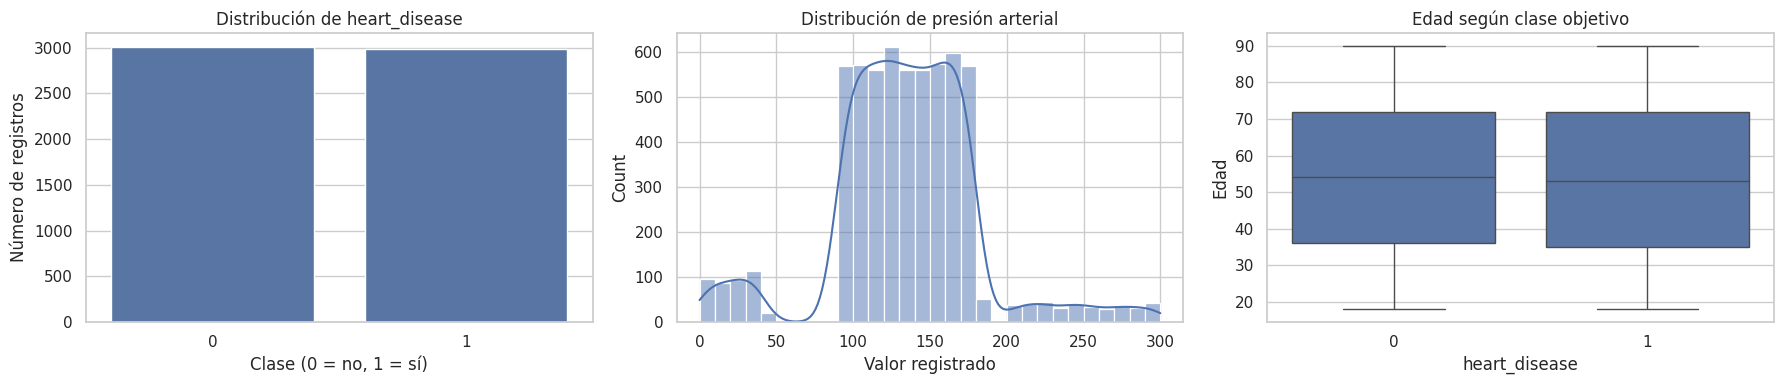

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.countplot(data=df, x=TARGET, ax=axes[0])
axes[0].set_title("Distribución de heart_disease")
axes[0].set_xlabel("Clase (0 = no, 1 = sí)")
axes[0].set_ylabel("Número de registros")

sns.histplot(data=df, x="blood_pressure", bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribución de presión arterial")
axes[1].set_xlabel("Valor registrado")

sns.boxplot(data=df, x=TARGET, y="age", ax=axes[2])
axes[2].set_title("Edad según clase objetivo")
axes[2].set_xlabel("heart_disease")
axes[2].set_ylabel("Edad")

plt.tight_layout()
plt.show()


## 5. Preparación correcta: separar antes de imputar

No se imputan valores en todo el dataset antes de la partición. Se separan primero las características y el objetivo, y luego entrenamiento y prueba. Las imputaciones, escalado y codificación quedan dentro de `Pipeline` y `ColumnTransformer`.

Las columnas codificadas como categorías se tratan como categóricas para evitar interpretar, por ejemplo, los códigos de tipo de dolor de pecho como magnitudes continuas. Esta decisión debe validarse con el diccionario de datos del conjunto.


In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].astype(int).copy()

# Se consideran categóricas las variables codificadas y las de texto.
categorical_features = [
    c for c in ["gender", "chest_pain_type", "exercise_angina",
                "hypertension", "residence_type", "smoking_status"]
    if c in X.columns
]
numeric_features = [c for c in X.columns if c not in categorical_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Variables numéricas:", numeric_features)
print("Variables categóricas:", categorical_features)


Entrenamiento: (4800, 15) | Prueba: (1200, 15)
Variables numéricas: ['age', 'blood_pressure', 'cholesterol', 'max_heart_rate', 'plasma_glucose', 'skin_thickness', 'insulin', 'bmi', 'diabetes_pedigree']
Variables categóricas: ['gender', 'chest_pain_type', 'exercise_angina', 'hypertension', 'residence_type', 'smoking_status']


## 6. Comparación inicial con validación cruzada

Se incluye `DummyClassifier` como referencia mínima: permite comprobar si los modelos aprenden patrones por encima de una estrategia ingenua. Se comparan Regresión Logística, Árbol de Decisión y Random Forest mediante validación cruzada estratificada de cinco particiones.

Se reportan accuracy, precision, recall, F1 y ROC-AUC. En este problema se presta especial atención al recall de la clase positiva, sin ignorar precision y falsos positivos.


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

modelos_base = {
    "Dummy (referencia)": DummyClassifier(strategy="prior"),
    "Regresión Logística": LogisticRegression(max_iter=2000, random_state=42),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, random_state=42, n_jobs=-1
    )
}

resultados_cv = []
pipelines_base = {}

for nombre, estimador in modelos_base.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimador)
    ])
    pipelines_base[nombre] = pipe
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=-1, error_score="raise"
    )
    fila = {"Modelo": nombre}
    for metrica in scoring:
        fila[f"{metrica}_media"] = scores[f"test_{metrica}"].mean()
        fila[f"{metrica}_desv"] = scores[f"test_{metrica}"].std()
    resultados_cv.append(fila)

tabla_cv = pd.DataFrame(resultados_cv).sort_values("f1_media", ascending=False)
display(tabla_cv.round(4))


,Modelo,accuracy_media,accuracy_desv,precision_media,precision_desv,recall_media,recall_desv,f1_media,f1_desv,roc_auc_media,roc_auc_desv
3,Random Forest,0.5037,0.0100,0.5020,0.0102,0.4864,0.0180,0.4939,0.0124,0.5076,0.0117
2,Árbol de Decisión,0.4960,0.0175,0.4939,0.0181,0.4739,0.0215,0.4836,0.0192,0.4960,0.0174
1,Regresión Logística,0.4935,0.0137,0.4908,0.0141,0.4659,0.0318,0.4778,0.0223,0.4991,0.0111
0,Dummy (referencia),0.5019,0.0004,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000


## 7. Optimización de hiperparámetros con F1-score

Se optimiza cada algoritmo mediante `GridSearchCV` con validación cruzada estratificada de cinco particiones, utilizando **F1-score** como criterio de selección. F1 equilibra precisión y sensibilidad (recall) para la clase positiva; evita elegir un modelo solo porque marca casi todos los pacientes como positivos.

**Importante:** optimizar F1 no garantiza alcanzar el 70 % de accuracy. Los resultados se deben reportar tal como se obtengan, comparándolos con el modelo Dummy y señalando las limitaciones de este dataset.

In [7]:
busquedas = {
    "Regresión Logística": (
        LogisticRegression(max_iter=2500, random_state=42),
        {
            "classifier__C": [0.01, 0.1, 1, 10],
            "classifier__class_weight": [None, "balanced"]
        }
    ),
    "Árbol de Decisión": (
        DecisionTreeClassifier(random_state=42),
        {
            "classifier__max_depth": [3, 5, 8, None],
            "classifier__min_samples_leaf": [1, 5, 10],
            "classifier__class_weight": [None, "balanced"]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1),
        {
            "classifier__max_depth": [None, 8, 15],
            "classifier__min_samples_leaf": [1, 5],
            "classifier__class_weight": [None, "balanced"]
        }
    )
}

busquedas_resultado = {}
resumen_busquedas = []

for nombre, (estimador, parametros) in busquedas.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimador)
    ])
    busqueda = GridSearchCV(
        estimator=pipe,
        param_grid=parametros,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )
    busqueda.fit(X_train, y_train)
    busquedas_resultado[nombre] = busqueda
    resumen_busquedas.append({
        "Modelo": nombre,
        "F1 CV": busqueda.best_score_,
        "Mejores parámetros": busqueda.best_params_
    })

display(pd.DataFrame(resumen_busquedas).sort_values("F1 CV", ascending=False))


,Modelo,F1 CV,Mejores parámetros
1,Árbol de Decisión,0.628608,"{'classifier__class_weight': 'balanced', 'clas..."
2,Random Forest,0.512585,"{'classifier__class_weight': 'balanced', 'clas..."
0,Regresión Logística,0.489179,"{'classifier__C': 0.01, 'classifier__class_wei..."


## 8. Selección y evaluación final en el conjunto de prueba

Se selecciona el modelo con el mejor **F1 promedio en validación cruzada**, calculado exclusivamente sobre entrenamiento. Luego se evalúa sobre el conjunto de prueba reservado, sin volver a ajustar hiperparámetros usando esos resultados. Se reportan accuracy, precision, recall, F1, balanced accuracy, ROC-AUC y matriz de confusión. Un valor cercano a 0,5 frente a un Dummy similar indica que el modelo no demuestra utilidad predictiva, aunque tenga recall alto.

Selección por mejor F1 en validación cruzada: Árbol de Decisión


,Resultado
Modelo seleccionado,Árbol de Decisión
Accuracy,0.486667
Precision,0.492049
Recall,0.931438
F1-score,0.643931
Balanced accuracy,0.488144
ROC-AUC,0.478268


Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.40      0.04      0.08       602
           1       0.49      0.93      0.64       598

    accuracy                           0.49      1200
   macro avg       0.44      0.49      0.36      1200
weighted avg       0.44      0.49      0.36      1200



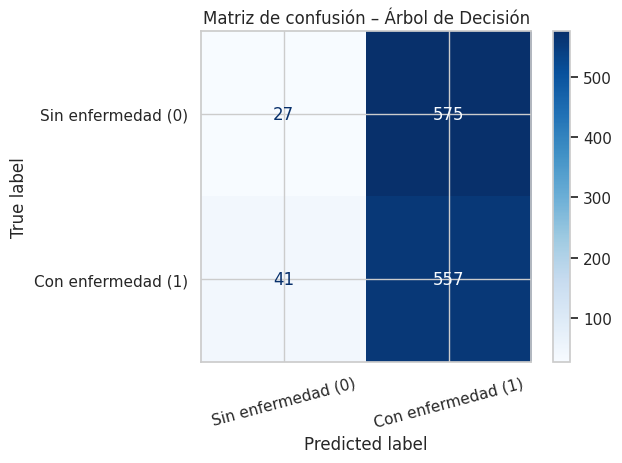

In [8]:
mejor_nombre = max(
    busquedas_resultado,
    key=lambda nombre: busquedas_resultado[nombre].best_score_
)
modelo_final = busquedas_resultado[mejor_nombre].best_estimator_
print("Selección por mejor F1 en validación cruzada:", mejor_nombre)

y_pred = modelo_final.predict(X_test)
y_prob = modelo_final.predict_proba(X_test)[:, 1] if hasattr(modelo_final, "predict_proba") else None

metricas_finales = {
    "Modelo seleccionado": mejor_nombre,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan
}
display(pd.DataFrame([metricas_finales]).T.rename(columns={0: "Resultado"}).round(4))

print("Reporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Sin enfermedad (0)", "Con enfermedad (1)"],
    cmap="Blues", values_format="d"
)
plt.title(f"Matriz de confusión – {mejor_nombre}")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 9. Comprobación de la predicción con un registro conocido

Se toma un registro del conjunto de prueba y se compara la predicción directa del modelo con la predicción del mismo registro mediante una copia del pipeline. Esta prueba permite verificar consistencia para el caso seleccionado.



In [9]:
registro_prueba = X_test.iloc[[0]].copy()
prediccion_registro = modelo_final.predict(registro_prueba)[0]

print("Datos del registro:")
display(registro_prueba)
print("Predicción:", int(prediccion_registro))
print("Valor real:", int(y_test.iloc[0]))

if hasattr(modelo_final, "predict_proba"):
    print("Probabilidades por clase:", modelo_final.predict_proba(registro_prueba)[0])

# Verificación de consistencia: el mismo pipeline debe devolver el mismo resultado.
prediccion_repetida = modelo_final.predict(registro_prueba)[0]
assert prediccion_registro == prediccion_repetida
print("Verificación: la predicción es consistente.")


Datos del registro:


,age,gender,chest_pain_type,blood_pressure,cholesterol,max_heart_rate,exercise_angina,plasma_glucose,skin_thickness,insulin,bmi,diabetes_pedigree,hypertension,residence_type,smoking_status
3292,47,0.0,2,23,158,211,1,158.0,48.0,158.0,19.536761,1.763908,1,Rural,Non-Smoker


Predicción: 1
Valor real: 0
Probabilidades por clase: [0.4343469 0.5656531]
Verificación: la predicción es consistente.


## 10. Auditoría adicional de calidad y señal predictiva

Esta revisión responde al requisito de investigar resultados inferiores al 70 %. **No se alteran los valores ni las etiquetas del dataset**. Se examinan distribuciones, señales predictivas, duplicados y un contraste con etiquetas permutadas. La evaluación final sobre `X_test` permanece separada de la selección de modelos.

In [10]:
# Calidad y distribuciones por clase
print("Filas y columnas:", df.shape)
print("Distribución de la clase objetivo:")
display(df[TARGET].value_counts(dropna=False).rename("Cantidad").to_frame())
print("Valores ausentes:")
display(df.isna().sum().sort_values(ascending=False).rename("Ausentes").to_frame())
print("Duplicados exactos:", int(df.duplicated().sum()))
print("Duplicados de predictores:", int(X.duplicated().sum()))

# Posibles valores físicamente inusuales: solo se informan, no se corrigen sin diccionario de datos.
for col in ["blood_pressure", "cholesterol", "max_heart_rate", "bmi", "plasma_glucose"]:
    if col in df.columns:
        print(f"{col}: mínimo={df[col].min():.3f}, máximo={df[col].max():.3f}, ceros={(df[col] == 0).sum()}")

print("Medias por clase para variables numéricas:")
display(df.groupby(TARGET)[numeric_features].mean().T.round(3))

Filas y columnas: (6000, 16)
Distribución de la clase objetivo:


,Cantidad
heart_disease,
0,3011
1,2989


Valores ausentes:


,Ausentes
skin_thickness,614
plasma_glucose,609
insulin,568
gender,472
residence_type,455
blood_pressure,0
chest_pain_type,0
age,0
exercise_angina,0
max_heart_rate,0


Duplicados exactos: 0
Duplicados de predictores: 0
blood_pressure: mínimo=0.000, máximo=300.000, ceros=11
cholesterol: mínimo=120.000, máximo=300.000, ceros=0
max_heart_rate: mínimo=70.000, máximo=220.000, ceros=0
bmi: mínimo=10.007, máximo=49.999, ceros=0
plasma_glucose: mínimo=70.000, máximo=250.000, ceros=0
Medias por clase para variables numéricas:


heart_disease,0,1
age,53.929,53.385
blood_pressure,134.774,133.776
cholesterol,209.596,210.095
max_heart_rate,144.739,145.255
plasma_glucose,161.302,160.936
skin_thickness,60.033,59.897
insulin,129.510,129.692
bmi,29.811,30.073
diabetes_pedigree,1.291,1.298


### 10.1. ¿Qué tan diferentes son las clases?

Se calcula el tamaño del efecto estandarizado para cada variable numérica. Valores cercanos a cero indican que las medias de ambas clases son similares; esto **no prueba** ausencia total de señal, pues podrían existir relaciones no lineales o interacciones.

In [11]:
# Diferencia estandarizada de medias (Cohen d aproximado)
import numpy as np
filas_efecto = []
for col in numeric_features:
    a = pd.to_numeric(X_train.loc[y_train == 0, col], errors="coerce").dropna()
    b = pd.to_numeric(X_train.loc[y_train == 1, col], errors="coerce").dropna()
    sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    d = (b.mean() - a.mean()) / sd if sd > 0 else np.nan
    filas_efecto.append({"Variable": col, "Diferencia estandarizada": d, "Magnitud absoluta": abs(d)})
tabla_efectos = pd.DataFrame(filas_efecto).sort_values("Magnitud absoluta", ascending=False)
display(tabla_efectos.round(4))

print("Proporciones por clase en variables categóricas (entrenamiento):")
for col in categorical_features:
    print("\n", col)
    display(pd.crosstab(X_train[col].fillna("Sin dato"), y_train, normalize="columns").round(3))

,Variable,Diferencia estandarizada,Magnitud absoluta
0,age,-0.0288,0.0288
1,blood_pressure,-0.0262,0.0262
8,diabetes_pedigree,0.0242,0.0242
3,max_heart_rate,0.0235,0.0235
5,skin_thickness,-0.0195,0.0195
7,bmi,0.0187,0.0187
6,insulin,-0.0068,0.0068
4,plasma_glucose,0.0055,0.0055
2,cholesterol,-0.0010,0.0010


Proporciones por clase en variables categóricas (entrenamiento):

 gender


heart_disease,0,1
gender,,
0.0,0.457,0.456
1.0,0.462,0.468
Sin dato,0.081,0.076



 chest_pain_type


heart_disease,0,1
chest_pain_type,,
1,0.252,0.239
2,0.235,0.260
3,0.242,0.252
4,0.271,0.248



 exercise_angina


... (3 outputs left out)


 residence_type


heart_disease,0,1
residence_type,,
Rural,0.464,0.464
Sin dato,0.073,0.072
Urban,0.462,0.463



 smoking_status


heart_disease,0,1
smoking_status,,
Non-Smoker,0.472,0.447
Smoker,0.455,0.468
Unknown,0.073,0.085


### 10.2. Prueba de etiquetas permutadas

Se compara el ROC-AUC de una regresión logística con la distribución obtenida al mezclar aleatoriamente las etiquetas **solo del conjunto de entrenamiento**. Esta prueba exploratoria usa 30 permutaciones y 3 particiones; el valor p tiene resolución limitada. Un resultado no significativo no demuestra que los datos sean aleatorios, pero sí impide afirmar una señal predictiva clara con este modelo.

ROC-AUC observado (CV): 0.5020
ROC-AUC medio con etiquetas permutadas: 0.5009
Valor p aproximado: 0.4194


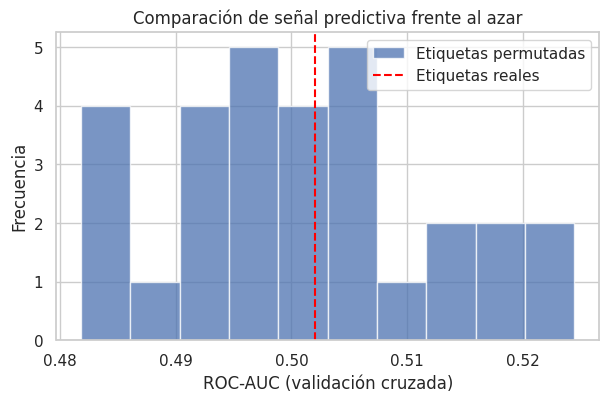

In [12]:
from sklearn.model_selection import permutation_test_score

modelo_auditoria = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])
cv_auditoria = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
score_real, scores_permutados, p_valor = permutation_test_score(
    modelo_auditoria, X_train, y_train,
    scoring="roc_auc", cv=cv_auditoria,
    n_permutations=30, n_jobs=-1, random_state=42
)
print(f"ROC-AUC observado (CV): {score_real:.4f}")
print(f"ROC-AUC medio con etiquetas permutadas: {np.mean(scores_permutados):.4f}")
print(f"Valor p aproximado: {p_valor:.4f}")

plt.figure(figsize=(7, 4))
plt.hist(scores_permutados, bins=10, alpha=0.75, label="Etiquetas permutadas")
plt.axvline(score_real, color="red", linestyle="--", label="Etiquetas reales")
plt.xlabel("ROC-AUC (validación cruzada)")
plt.ylabel("Frecuencia")
plt.legend()
plt.title("Comparación de señal predictiva frente al azar")
plt.show()

## 10. Guardar el pipeline completo para Streamlit

Después de ejecutar y revisar la nueva evaluación, se guarda el pipeline completo (preprocesamiento + clasificador). Este archivo no es el dataset: es el modelo entrenado. La aplicación de Streamlit se cargará con `joblib.load()` y se utilizará `predict()` o `predict_proba()`.

In [13]:
import joblib
import sklearn
from pathlib import Path

RUTA_MODELO = "pipeline_heart_disease.joblib"
joblib.dump(modelo_final, RUTA_MODELO)

print("Pipeline guardado en:", RUTA_MODELO)
print("Versión de scikit-learn:", sklearn.__version__)


Pipeline guardado en: pipeline_heart_disease.joblib
Versión de scikit-learn: 1.6.1


## 11. Registro de uso de inteligencia artificial

**Herramienta:** ChatGPT y Gemini.  
**Propósito:** apoyar la revisión del pipeline, identificar riesgos de fuga de información, proponer estructura de validación cruzada y preparar la serialización del pipeline para Streamlit.

**Prompt principal utilizado:** “Revisa el notebook de clasificación de enfermedad cardíaca, identifica posibles problemas de preprocesamiento y fuga de información, y propón una estructura reproducible con imputación dentro del pipeline, validación cruzada estratificada, comparación de modelos y evaluación final”.

**Ajustes y decisiones del estudiante:** completar con los cambios realizados después de ejecutar y revisar los resultados.


## Conclusión final de la auditoría del modelo

Durante el desarrollo de este proyecto de minería de datos se implementaron y evaluaron diferentes algoritmos de clasificación para predecir la presencia de enfermedades cardíacas a partir de un conjunto de datos de 6.000 pacientes. Se utilizaron modelos como Regresión Logística, Árbol de Decisión y Random Forest, aplicando técnicas de preprocesamiento, validación cruzada y optimización de hiperparámetros.

El modelo seleccionado fue el Árbol de Decisión, que obtuvo una exactitud (accuracy) del **48,67 %**, una precisión del **49,20 %**, un recall del **93,14 %** y un F1-score del **64,39 %**. Aunque presentó un recall elevado, también produjo numerosos falsos positivos, lo que demuestra dificultades para distinguir correctamente entre pacientes con y sin enfermedad cardíaca.

Al comparar los resultados con el modelo Dummy, cuya exactitud fue aproximadamente del 50,19 %, se observó que los algoritmos evaluados no lograron una mejora significativa frente a una clasificación de referencia. Asimismo, el ROC-AUC del modelo seleccionado fue del 47,83 %, cercano al valor de 0,5 que representa una discriminación equivalente al azar.

La auditoría adicional permitió identificar que las variables analizadas presentan diferencias muy pequeñas entre pacientes con y sin enfermedad cardíaca. Además, la prueba de permutación obtuvo un valor p de 0,4194, por lo que no se encontró evidencia estadística suficiente de una capacidad predictiva superior al azar. También se revisó la calidad de los datos, incluyendo valores ausentes y posibles valores atípicos o inverosímiles, evitando modificar arbitrariamente la información original.

En conclusión, aunque se completaron las etapas de preparación de datos, entrenamiento, evaluación, optimización y almacenamiento del modelo mediante Joblib, **el desempeño obtenido no es suficiente para considerar este sistema una herramienta de diagnóstico médico confiable**. Por esta razón, la aplicación desarrollada tendrá únicamente fines académicos y demostrativos.

Como mejora futura, se recomienda verificar con el docente la procedencia del dataset, la definición de sus variables y la calidad de las etiquetas de clasificación. También sería conveniente utilizar un conjunto de datos clínicamente validado que permita desarrollar modelos con mayor capacidad predictiva.

Finalmente, este proyecto permitió comprender que el éxito de un modelo de minería de datos no depende únicamente del algoritmo utilizado, sino también de la calidad, relevancia y capacidad informativa de los datos disponibles.